### IMPORTING LIBRARY

In [1]:
import os
import random
import datetime
import json
import h5py
import pacmap
import pandas                   as pd
import numpy                    as np
import plotly.express           as px
import plotly.graph_objects     as go

import matplotlib.pyplot        as plt

from tqdm                       import tqdm
from preProcessingData          import PreProcessData
from utility.matpilotDraw       import MatPlot
from utility.plotloyDraw        import PlotlyDraw
from prettytable                import PrettyTable
from model.vaeConv1DCustom      import vaeConv1DCustom 
from vaeTrainer                 import appVAE
from mpl_toolkits.mplot3d       import Axes3D
# from sklearn.cluster            import KMeans
# from sklearn.cluster            import DBSCAN
from sklearn.preprocessing      import StandardScaler, MinMaxScaler
from matplotlib.colors          import Normalize
from sklearn.mixture            import GaussianMixture



matPlot    = MatPlot() 
plotly     = PlotlyDraw()
preData    = PreProcessData()

2024-10-18 12:29:50.004712: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-18 12:29:50.123369: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2024-10-18 12:29:50.123387: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2024-10-18 12:29:50.153482: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-18 12:29:50.843560: W tensorflow/stream_executor/platform/de

### PACMAP

In [2]:
# ===================================
# Handle the data
# -----------------------------------
rawData                     = preData.loadCriticalData()                    # Load the data from critical file
addedVariablesData          = preData.additionEfficiencyVar(rawData)        # Add some additional efficiency variable

# healthyData,_               = preData.getHealthyState(rawData)              # Load the healthy state
# normalizedHealthy           = preData.normalizeBuilinFunction(healthyData,  scaler = MinMaxScaler())              # Normalize the healthy data
normalizedAllData           = preData.normalizeBuilinFunction(addedVariablesData,  scaler = MinMaxScaler())         # Normalize the all data
normalizedHealthy,_         = preData.getHealthyState(normalizedAllData)       # Load the healthy state
trajectory                  = preData.getTrajectory(normalizedAllData)         # Extract the trajectory



print(normalizedHealthy.shape, normalizedAllData.shape)

Process:40276||2024-10-18 12:29:53,834-INFO [preProcessingData.py:loadCriticalData():255]:Loading critical MOF data from files ...
Process:40276||2024-10-18 12:29:54,246-INFO [preProcessingData.py:loadCriticalData():261]:Finish loading data from files ...


29
No NaN values found in the signal.
0           6.745416
1           6.641729
2           5.572386
3           2.938572
4           0.216141
             ...    
321430     12.580554
321431      7.970535
321432      4.327841
321433    119.592469
321434      7.333398
Length: 321435, dtype: float64
10540294643.46864
429415232736.1494
0           6.745416
1           6.641729
2           5.572386
3           2.938572
4           0.216141
             ...    
321430     12.580554
321431      7.970535
321432      4.327841
321433    119.592469
321434      7.333398
Name: Eficiencia_Rendimiento, Length: 321435, dtype: float64
0         2097.669434
1         2101.374268
2         2110.250000
3         1481.219849
4           27.148882
             ...     
321430    1770.398193
321431    1728.805298
321432    1691.649902
321433    1907.612427
321434    2116.771240
Name: rendimiento(ton), Length: 321435, dtype: float64
0         310.977020
1         316.389648
2         378.697723
3         50

Process:40276||2024-10-18 12:29:57,094-INFO [preProcessingData.py:getHealthyState():652]:Getting critical trajectories ...


(79188, 49) (321435, 49)


##### FOR EFFICIENCY DATA

['lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'salmon', 'salmon', 'salmon', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'navy', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'salmon', 'salmon', 'navy', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'navy', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'navy', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'salmon', 'navy', 'lightblue', 'lightblue', 'lightblue', 'lightblue', 'salmon', 'navy', 'lightblue', 'lightblue', 'lightblue', 'navy', 'navy', 'lightb

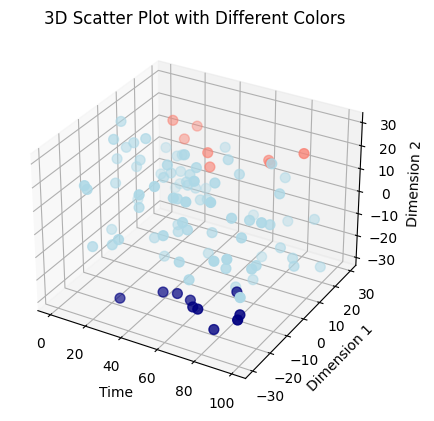

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Generate sample data
np.random.seed(0)  # For reproducibility
num_points = 100
time = np.linspace(0, 100, num_points)  # Time from 0 to 100
dim1 = np.random.uniform(-30, 30, num_points)  # Random values for dim1
dim2 = np.random.uniform(-30, 30, num_points)  # Random values for dim2

# Create color list based on some criteria
# Here we'll use a simple condition to create colors
colors = []
for d1, d2 in zip(dim1, dim2):
    if d1 > 10 and d2 > 10:
        colors.append('salmon')  # Color for points where both dim1 and dim2 are greater than 10
    elif d1 < -10 and d2 < -10:
        colors.append('navy')    # Color for points where both dim1 and dim2 are less than -10
    else:
        colors.append('lightblue')  # Color for all other points

# Create a 3D scatter plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

print(colors)
# Scatter the points
scatter = ax.scatter(time, dim1, dim2, c=colors, s=50)

# Set labels
ax.set_xlabel('Time')
ax.set_ylabel('Dimension 1')
ax.set_zlabel('Dimension 2')

# Add a title
ax.set_title('3D Scatter Plot with Different Colors')

# Show the plot
plt.show()

In [4]:
pacmapModel                 = pacmap.PaCMAP(    n_components = 2, 
                                                random_state = 40, 
                                                save_tree    = True)

clusterAlg                  = GaussianMixture(  n_components = 5, 
                                                random_state = 3, 
                                                n_init       = 5)
pacmapModel.fit(normalizedHealthy[preData.efficiencyCr1])            # Train with the healthy data

PaCMAP(pair_FP=array([[    0, 11590],
       [    0,   931],
       [    0, 76820],
       ...,
       [79187, 11814],
       [79187, 55200],
       [79187, 42102]], dtype=int32),
       pair_MN=array([[    0, 11590],
       [    0, 50777],
       [    0,   860],
       ...,
       [79187, 55472],
       [79187, 76047],
       [79187, 25333]], dtype=int32),
       pair_neighbors=array([[    0, 71387],
       [    0, 62479],
       [    0, 32223],
       ...,
       [79187, 59157],
       [79187, 79186],
       [79187, 65312]], dtype=int32),
       random_state=40, save_tree=True)

The MOF Válvula defectuosa
(-10, 0) (-10, 0)
(10, 20) (-10, 0)
(0, 10) (10, 20)
(-10, 0) (-10, 0)
(10, 20) (-10, 0)
['salmon', 'salmon', 'salmon', 'salmon', 'navy', 'navy', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'navy', 'navy', 'navy', 'salmon', 'salmon', 'salmon',

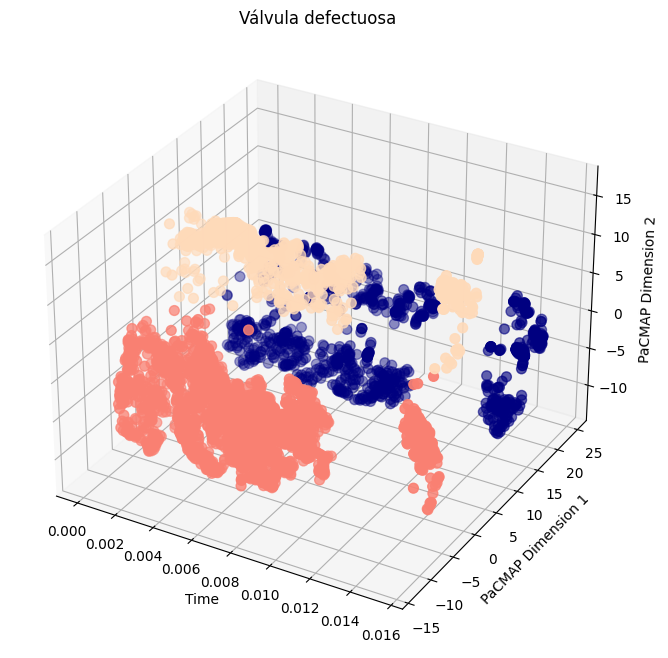

(10, 20) (-10, 0)
(0, 10) (10, 20)
(-10, 0) (0, 10)
(20, 30) (0, 10)
(10, 20) (-10, 0)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'teal', 'peachpuff', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'violet', 'violet', 'navy', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'navy', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'violet', 'navy', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpu

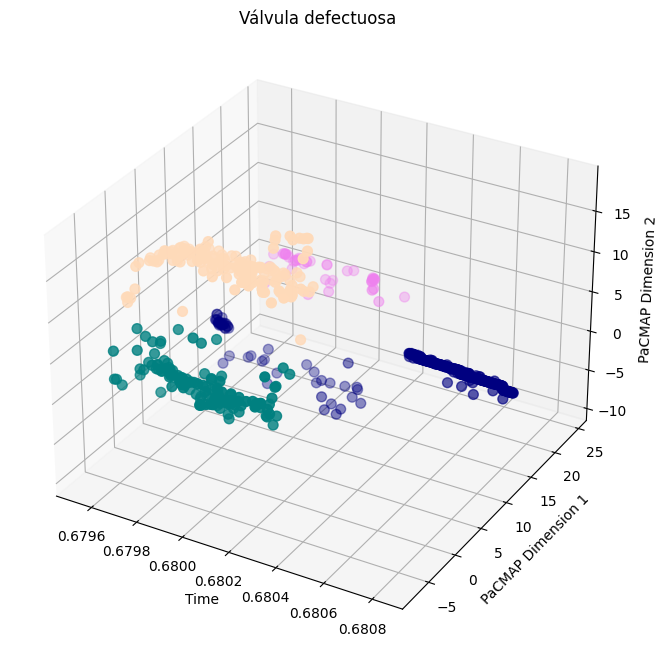

(0, 10) (10, 20)
(-10, 0) (0, 10)
(10, 20) (-10, 0)
(-10, 0) (-10, 0)
(-10, 0) (-10, 0)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'navy', 'navy', 'navy', 'navy', 'navy', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'peachpuff', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'salmon', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'peachpuff', 'peachpuff', 'teal', 'teal', 'teal', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peac

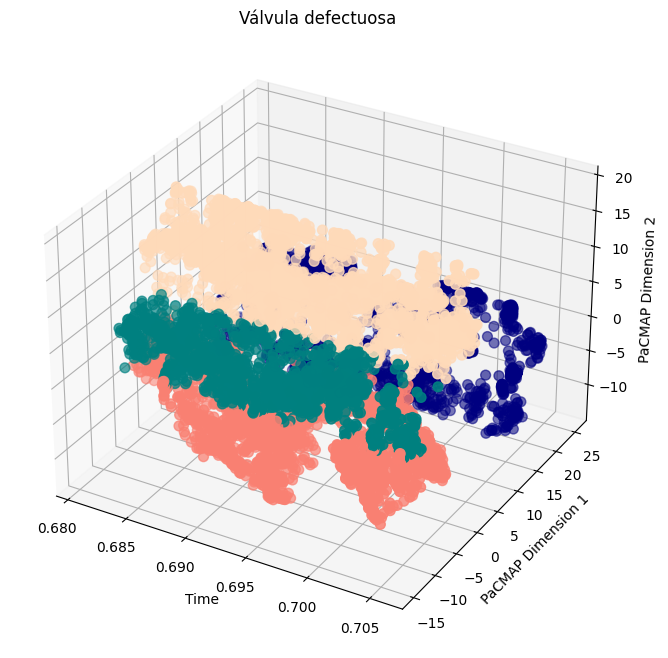

The MOF Falta de aceite hidráulico
(-20, -10) (-10, 0)
(10, 20) (-10, 0)
(-10, 0) (-20, -10)
(-10, 0) (0, 10)
(10, 20) (-20, -10)
['navy', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'teal', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'teal', 'teal', 'teal', 'teal', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'teal', 'teal', 'navy', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'teal', 'teal', 'teal', 'cyan', 'cyan', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'teal', 'teal', 'teal', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgree

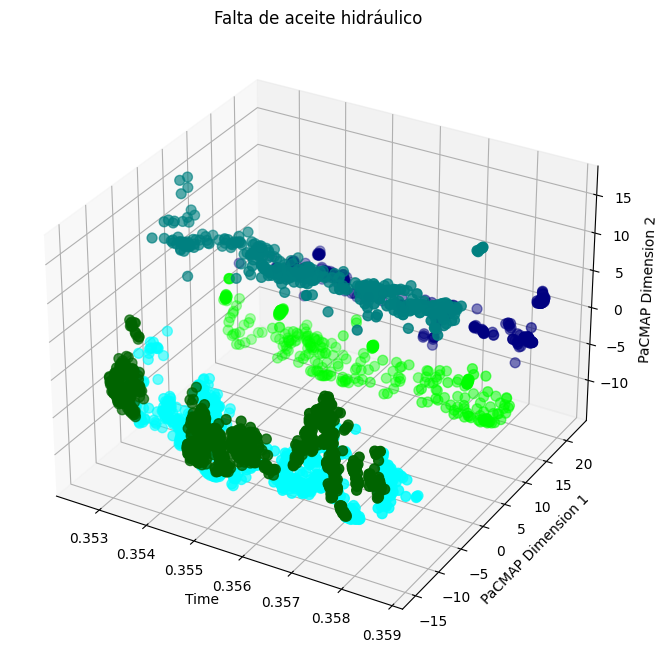

The MOF Lubricación  deficiente
(0, 10) (10, 20)
(10, 20) (-10, 0)
(-10, 0) (-10, 0)
(0, 10) (10, 20)
(10, 20) (0, 10)
['navy', 'navy', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'peachpuff', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'peachpuff', 'salmon', 'salmon', 'salmon', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'salmon', 'navy', 'navy', 'salmon', 'salmon', 'peachpuff', 'peachpuff', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'peachpuff', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 

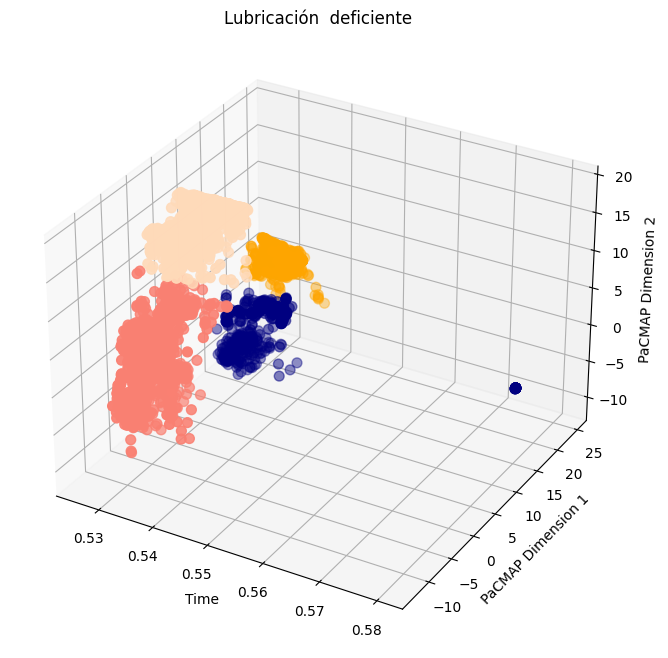

(10, 20) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-10, 0)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy']


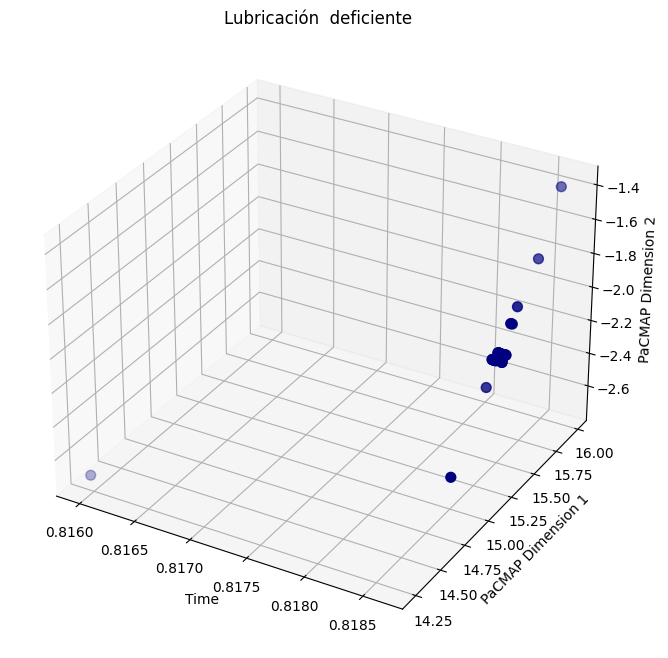

The MOF Temperatura fuera de rango
(0, 10) (10, 20)
(10, 20) (0, 10)
(-10, 0) (0, 10)
(10, 20) (-20, -10)
(10, 20) (-10, 0)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'peachpuff', 'peachpuff', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'teal', 'teal', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'orange', 'orange', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpu

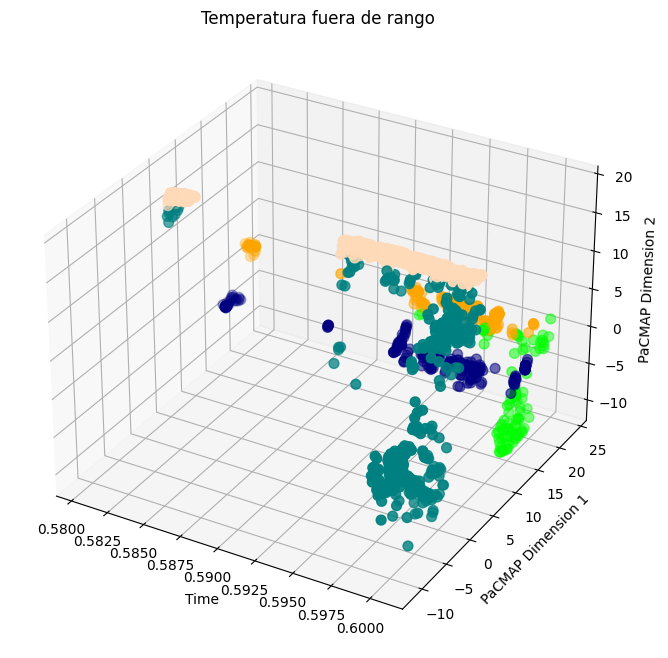

The MOF Bomba hidráulica con fuga
(-10, 0) (0, 10)
(20, 30) (0, 10)
(-10, 0) (10, 20)
(10, 20) (-10, 0)
(0, 10) (10, 20)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'navy', 'navy', 'navy', 'navy', 'teal', 'navy', 'lavender', 'lavender', 'lavender', 'teal', 'teal', 'teal', 'teal', 'teal', 'lavender', 'lavender', 'lavender', 'lavender', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'violet', 'violet', 'navy', 'navy', 'navy', 'navy', 'navy', 'lavender', 'lavender', 'lavender', 'peachpuff', 'teal', 'teal', 'lavender', 'lavender', 'lavender', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'lavender

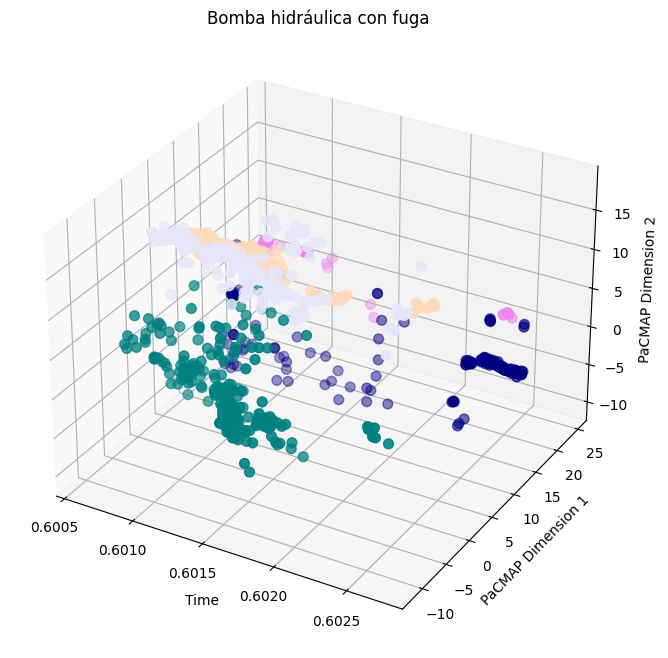

(0, 10) (0, 10)
(-10, 0) (-10, 0)
(10, 20) (-20, -10)
(-10, 0) (-10, 0)
(10, 20) (-10, 0)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', '

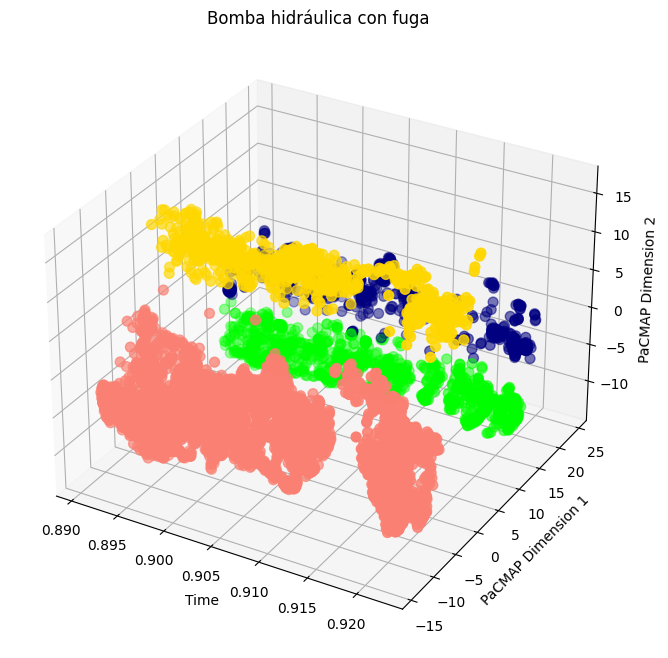

The MOF Fuga de aceite
(0, 10) (0, 10)
(10, 20) (-10, 0)
(-10, 0) (-10, 0)
(10, 20) (-10, 0)
(-10, 0) (10, 20)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'lavender', 'lavender', 'salmon', 'salmon', 'salmon', 'salmon', 'lavender', 'lavender', 'gold', 'gold', 'gold', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'gold', 'navy', 'navy', 'navy', 'navy', 'navy', 'lavender', 'lavender', 'gold', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'gold', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'salmon', 'lavender', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'lavender', 'gold', 'gold', 'gold', 'gold', 'navy', 'navy', 'salmon', 'salmon', 'salmon'

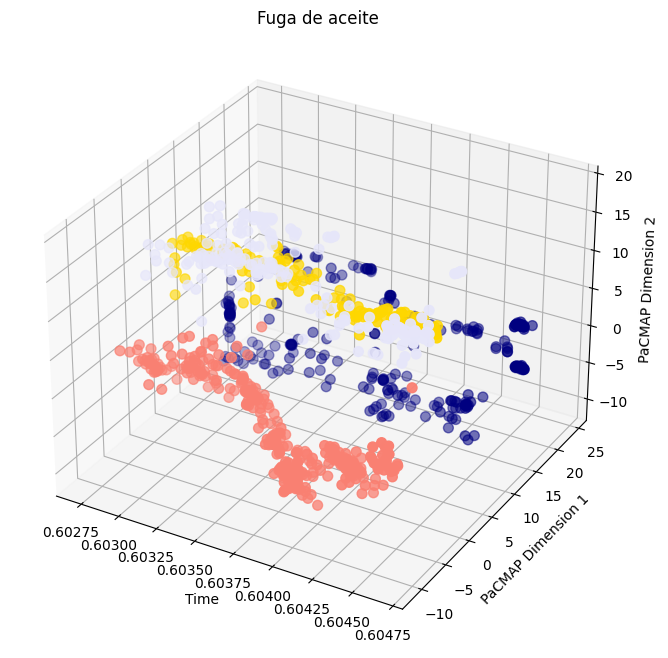

(20, 30) (-10, 0)
(-10, 0) (-10, 0)
(-10, 0) (10, 20)
(10, 20) (-10, 0)
(0, 10) (0, 10)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'maroon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'maroon', 'maroon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'maroon', 'maroon', 'navy', 'navy', 'maroon', 'navy', 'maroon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'lavender', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'lavender', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'salmon', 'salmon', 'gold', 'salmon', 'salmon', 'sa

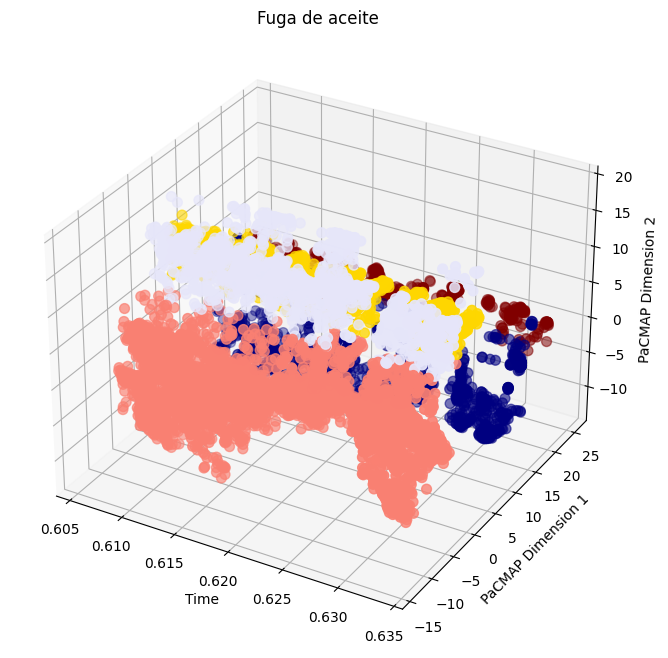

The MOF Falla sistema de hidroset-poste
(-20, -10) (-10, 0)
(0, 10) (0, 10)
(20, 30) (-10, 0)
(-10, 0) (0, 10)
(10, 20) (-10, 0)
['maroon', 'maroon', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'gold', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'gold', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'gold', 'maroon', 'navy', 'navy', 'navy', 'navy', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'gold', 'gold', 'gold', 'gold', 'maroon', 'maroon', 'maroon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'gold', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 't

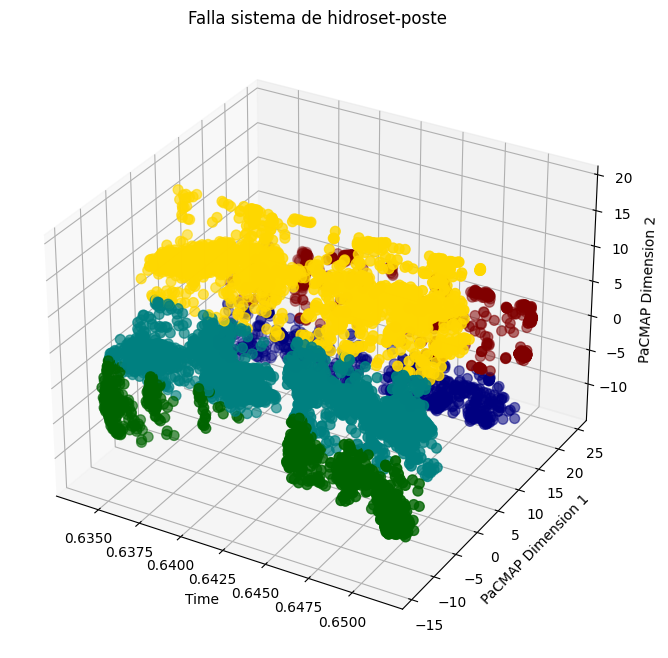

(0, 10) (0, 10)
(10, 20) (-10, 0)
(-10, 0) (-10, 0)
(10, 20) (-20, -10)
(-20, -10) (-10, 0)
['navy', 'navy', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'lime', 'lime', 'lime', 'lime', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'gold', 'gold', 'gold', 'navy', 'navy', 'lime', 'lime', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'lime', 'lime', 'navy', 'navy', 'navy', 'lime', 'lime', 'lime', 'lime', 'navy', 'gold', 'gold', 'gold', 'gold', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'gold', 'gold', 'gold', 'gold', 'navy', 'lime', 'lime', 'lime', 'lime', 'salmon', 'lime', 'lime', 'lime

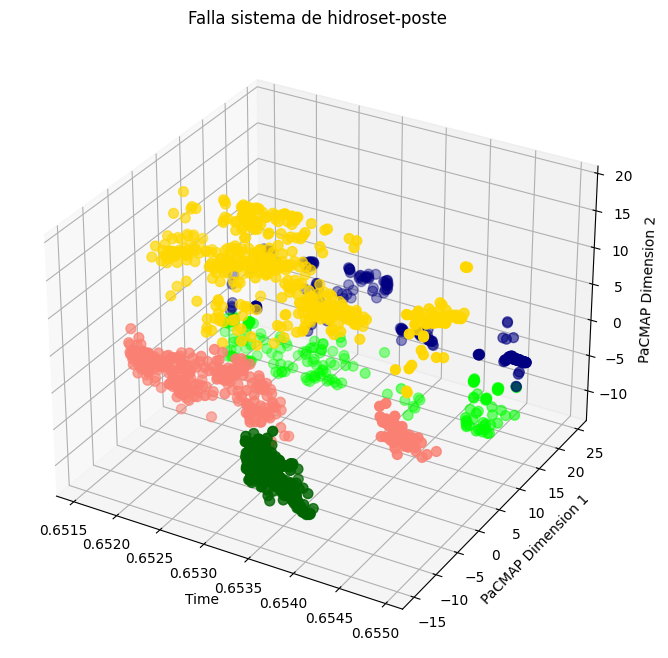

(10, 20) (-10, 0)
(-10, 0) (10, 20)
(10, 20) (-10, 0)
(0, 10) (10, 20)
(0, 10) (10, 20)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'lavender', 'lavender', 'lavender', 'lavender', 'peachpuff', 'peachpuff', 'peachpuff', 'peachpuff', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy']


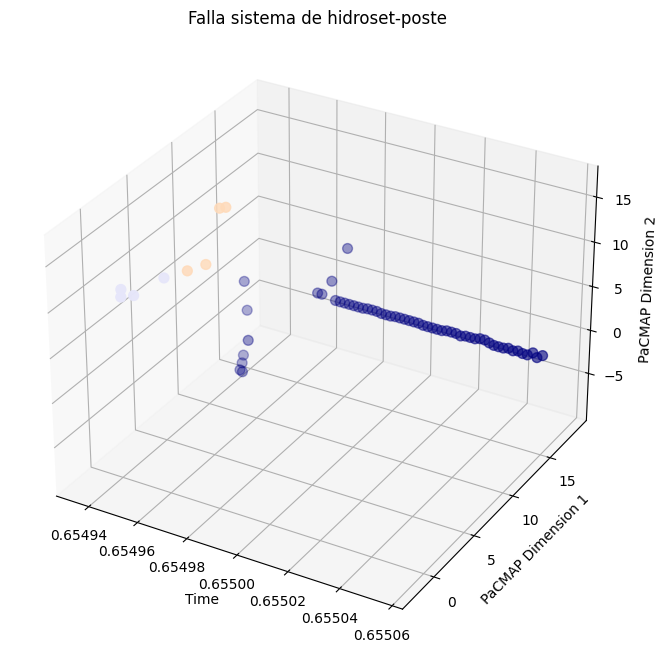

The MOF Mandibulas o revestimiento suelto
(-10, 0) (0, 10)
(20, 30) (-10, 0)
(-10, 0) (-10, 0)
(0, 10) (0, 10)
(10, 20) (-10, 0)
['navy', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'gold', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'gold', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroon', 'maroo

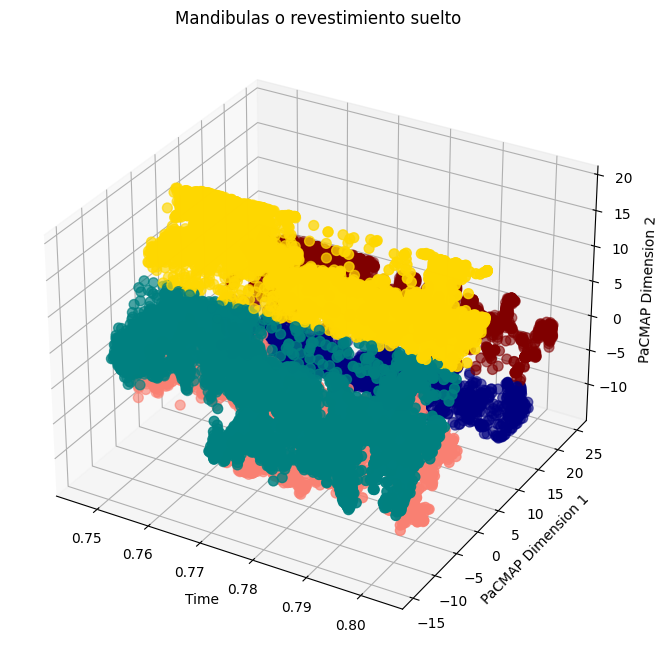

(10, 20) (-10, 0)
(0, 10) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-10, 0)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'violet', 'violet', 'navy', 'navy', 'violet', 'violet', 'navy', 'violet', 'violet', 'violet', 'navy', 'navy', 'violet', 'navy', 'navy', 'navy', 'violet', 'violet', 'navy', 'navy', 'violet', 'navy', 'navy', 'violet', 'navy', 'navy', 'navy', 'violet', 'navy', 'navy', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'navy', 'violet', 'violet', 'n

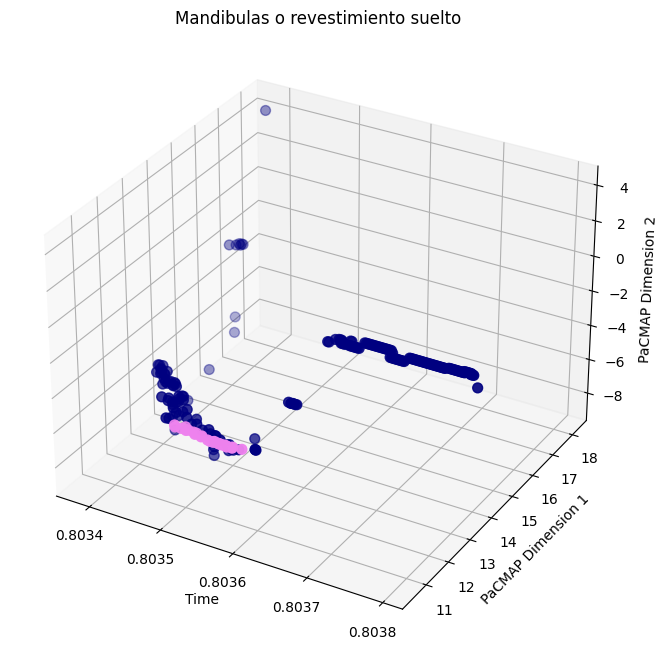

(10, 20) (-10, 0)
(10, 20) (-10, 0)
(0, 10) (10, 20)
(10, 20) (-10, 0)
(-10, 0) (0, 10)
['navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy',

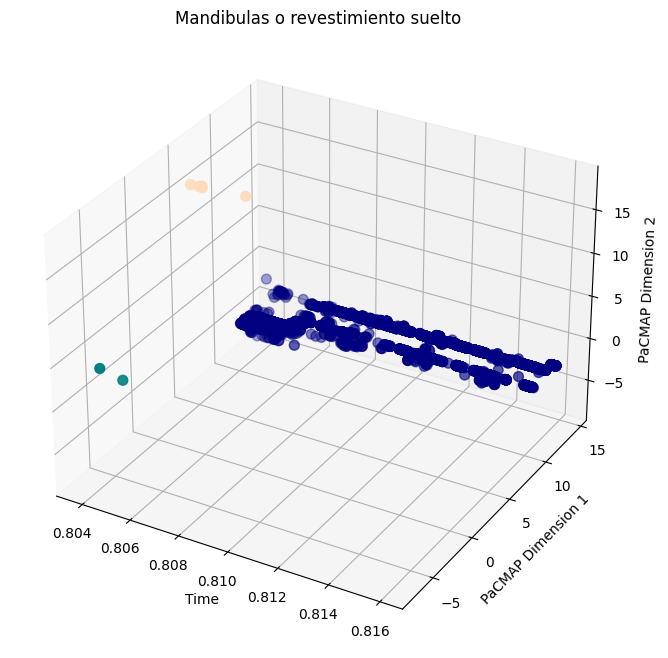

In [44]:
def get_color(dim1, dim2):
    # Define the ranges for both dimensions
    ranges = [(-30, -20), (-20, -10), (-10, 0), (0, 10), (10, 20), (20, 30)]
    
    # Define colors for the ranges combination
    color_map = {
    (-30, -20, -30, -20): 'red', 
    (-20, -10, -30, -20): 'green', 
    (-10, 0, -30, -20): 'blue',
    (0, 10, -30, -20): 'yellow', 
    (10, 20, -30, -20): 'orange', 
    (20, 30, -30, -20): 'purple',
    (-30, -20, -20, -10): 'pink', 
    (-20, -10, -20, -10): 'brown', 
    (-10, 0, -20, -10): 'cyan',
    (0, 10, -20, -10): 'magenta', 
    (10, 20, -20, -10): 'lime', 
    (20, 30, -20, -10): 'gray',
    (-30, -20, -10, 0): 'lightblue', 
    (-20, -10, -10, 0): 'darkgreen', 
    (-10, 0, -10, 0): 'salmon',
    (0, 10, -10, 0): 'violet', 
    (10, 20, -10, 0): 'navy', 
    (20, 30, -10, 0): 'maroon',
    (-30, -20, 0, 10): 'crimson', 
    (-20, -10, 0, 10): 'indigo', 
    (-10, 0, 0, 10): 'teal',
    (0, 10, 0, 10): 'gold', 
    (10, 20, 0, 10): 'orange', 
    (20, 30, 0, 10): 'violet',
    (-30, -20, 10, 20): 'coral', 
    (-20, -10, 10, 20): 'orchid', 
    (-10, 0, 10, 20): 'lavender',
    (0, 10, 10, 20): 'peachpuff', 
    (10, 20, 10, 20): 'khaki', 
    (20, 30, 10, 20): 'khaki',
    (-30, -20, 20, 30): 'lightgreen', 
    (-20, -10, 20, 30): 'lightgray', 
    (-10, 0, 20, 30): 'bisque',
    (0, 10, 20, 30): 'plum', 
    (10, 20, 20, 30): 'lightpink', 
    (20, 30, 20, 30): 'peru',
}
    
    # Helper function to find the correct range for a given value
    def find_range(val):
        for r in ranges:
            if r[0] <= val <= r[1]:  # <= to include boundaries correctly
                return r
        return None
    
    # Find the ranges for dim1 and dim2
    dim1_range = find_range(dim1)
    dim2_range = find_range(dim2)
    print(dim1_range,dim2_range)
    
    if dim1_range and dim2_range:
        # Get the color based on the range combination
        color = color_map.get((*dim1_range, *dim2_range), 'black')  # default to black if not found
    else:
        color = 'black'  # In case the values are out of bounds

    return color

# Test the function
# dim1 = 6.411041259765625
# dim2 = 11.2989501953125
# selected_color = get_color(dim1, dim2)
# print(f"Selected color for dim1={dim1} and dim2={dim2}: {selected_color}")

# 6.411041259765625 11.2989501953125

# Create a function to map both dimensions to colors

for mof, idxTrajectList in trajectory.items():
    print(f"The MOF {mof}")
    for idx,curTraject in enumerate(idxTrajectList):

        # -----------------------------
        # Transform the PACMAP
        # -----------------------------
        efficiencyTraject   = curTraject[preData.efficiencyCr1]     # Extract the 
        # print("--------------------")
        # print(efficiencyTraject.shape)
        embedding           = pacmapModel.transform(efficiencyTraject)
        dim1 = embedding[:, 0]  # First dimension from pacmap (size 100)
        dim2 = embedding[:, 1]  # Second dimension from pacmap (size 100)
        # print(embedding.shape)

        # -----------------------------
        # Cluster
        # -----------------------------
        clusters            = clusterAlg.fit_predict(embedding)
        clusterColor        = [None] * len(clusters)  # Initialize clusterColor to store strings
        clusterDim          = []

        maxCluster          = max(clusters)
        for idx in range(maxCluster+1):
            clusterLabel = idx
            # idxDim       = np.where(clusters == clusterLabel)       # Get the position of current label
            idxDim          = np.where(clusters == clusterLabel)[0]
            # print(idxDim)
            # Step 2: Generate the histogram
            counts1, bins1 = np.histogram(dim1[idxDim])
            max_bin_index1 = np.argmax(counts1)

            counts2, bins2 = np.histogram(dim2[idxDim])
            max_bin_index2 = np.argmax(counts2)

            # Step 4: Get the value of the bin's center with the highest count
            mostDim1 = (bins1[max_bin_index1] + bins1[max_bin_index1 + 1]) / 2
            mostDim2 = (bins2[max_bin_index2] + bins2[max_bin_index2 + 1]) / 2
            # print(mostDim1,mostDim2)

            color   = get_color(int(mostDim1),int(mostDim2))
            if color =="black":
                print(mostDim1,mostDim2)

            for i in idxDim:  # idxDim is a 1D array of indices
                clusterColor[i] = color

        # colorList = np.array(clusterColor)    
        colorList = clusterColor
        print(colorList)
        time       = curTraject["tiempo"]


        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')

        # Plot the data in 3D: X = time, Y = PaCMAP dim 1, Z = PaCMAP dim 2, color by cluster
        scatter = ax.scatter(time, dim1, dim2, c=colorList, s=50)

        # Labels for axes
        ax.set_xlabel('Time')
        ax.set_ylabel('PaCMAP Dimension 1')
        ax.set_zlabel('PaCMAP Dimension 2')

        # Title
        ax.set_title(mof)

        # Add color bar to show cluster information
        # cbar = plt.colorbar(scatter, ax=ax, pad=0.1)
        # cbar.set_label('Cluster')

        # Show plot
        plt.show()






        # # Combine both datasets to get global ranges for dim1 and dim2
        # combined_data = np.vstack([X_pacmap1, X_pacmap2])

        # # Get global min and max for both dimensions separately (dim1 and dim2)
        # min_val_dim1, min_val_dim2 = np.min(combined_data, axis=0)
        # max_val_dim1, max_val_dim2 = np.max(combined_data, axis=0)

        

        # # Create plots for comparison
        # fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

        # # Apply the colormap to Dataset 1
        # colors1 = get_colors(X_pacmap1)

        # # Plot Dataset 1
        # scatter1 = ax1.scatter(X_pacmap1[:, 0], X_pacmap1[:, 1], color=colors1, s=50)
        # ax1.set_title('Dataset 1 - PaCMAP')
        # ax1.set_xlabel('PaCMAP Dimension 1')
        # ax1.set_ylabel('PaCMAP Dimension 2')

        # # Apply the same colormap to Dataset 2
        # colors2 = get_colors(X_pacmap2)

        # # Plot Dataset 2
        # scatter2 = ax2.scatter(X_pacmap2[:, 0], X_pacmap2[:, 1], color=colors2, s=50)
        # ax2.set_title('Dataset 2 - PaCMAP')
        # ax2.set_xlabel('PaCMAP Dimension 1')
        # ax2.set_ylabel('PaCMAP Dimension 2')

        # # Add colorbar to show the mapping from values to colors
        # cbar = fig.colorbar(scatter1, ax=[ax1, ax2], orientation='vertical', pad=0.1)
        # cbar.set_label('Color based on Dim 1 and Dim 2')

        # plt.tight_layout()
        # plt.show()
        # -----------------------------
        # Plot
        # -----------------------------
        # testSignal = curTraject["Potencia(kW)"]
        # time       = curTraject["tiempo"]

        # norm    = Normalize(vmin=clusters.min(), vmax=clusters.max())
        # colors  = plt.cm.Spectral(norm(clusters))  # Use the 'Spectral' colormap

        # # Create subplots
        # fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), gridspec_kw={'height_ratios': [1, 0.5, 4]})

        # # Plot 1: Signal over time with color from cluster
        # for i in range(len(testSignal) - 1):
        #     ax1.plot(time[i:i+2], testSignal[i:i+2], color=colors[i])  # Plot segments of the signal with cluster color

        # ax1.set_title('Signal over Time', fontsize=14)
        # ax1.set_xlabel('Time')
        # ax1.set_ylabel('Signal')

        # # Plot 2: Colorbar for clusters
        # ax2.imshow([colors], aspect='auto')  # Display the color range horizontally
        # ax2.set_yticks([])  # Remove y-axis ticks
        # ax2.set_title('Cluster Color Bar')

        # # Plot 3: Clusters in 2D Reduced Space (PaCMAP embedding)
        # scatter = ax3.scatter(embedding[:, 0], embedding[:, 1], c=clusters, cmap='Spectral', s=50)
        # ax3.set_title('Clusters in 2D Reduced Space (PaCMAP)', fontsize=14)
        # ax3.set_xlabel('PaCMAP 1')
        # ax3.set_ylabel('PaCMAP 2')

        # # Add a colorbar for the clusters in the 2D space
        # fig.colorbar(scatter, ax=ax3, label='Cluster')

        # plt.tight_layout()
        # plt.show()

The MOF Válvula defectuosa
(0, 10) (-20, -10)
(-10, 0) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (0, 10)
(-10, 0) (-10, 0)
['salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'navy', 'navy', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmo

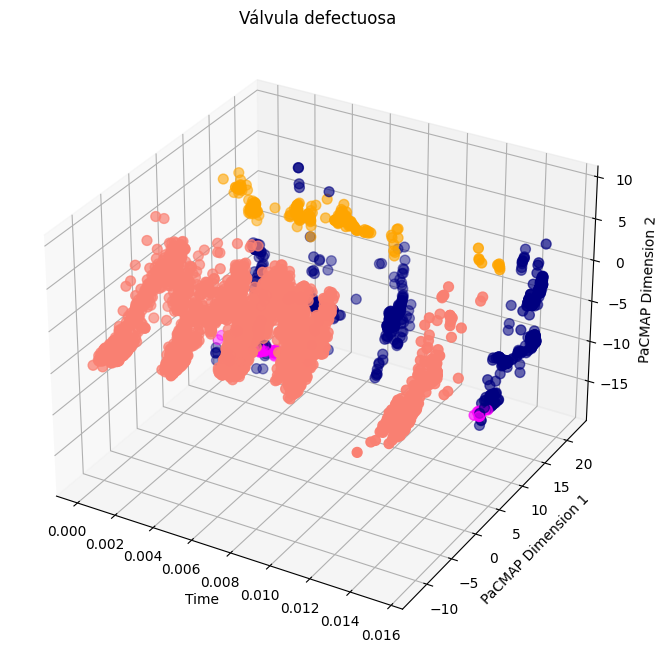

(-10, 0) (-20, -10)
(10, 20) (-10, 0)
(0, 10) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-20, -10)
['violet', 'lime', 'violet', 'violet', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'violet', 'violet', 'violet', 'violet', 'navy', 'navy', 'navy', 'navy', 'navy', 'cyan', 'cyan', 'cyan', 'cyan', 'violet', 'violet', 'violet', 'lime', 'violet', 'violet', 'violet', 'lime', 'lime', 'lime', 'cyan', 'cyan', 'cyan', 'cyan', 'violet', 'violet', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'cyan', 'cyan', 'cyan', 'violet', 'violet', 'lime', 'lime', 'cyan', 'cyan', 'cyan', 'cyan', 'violet', 'lime', 'lime', 'lime', 'lime', 'lime', 'cyan', 'cyan', 'cyan', 'cyan', 'violet', 'violet', 'violet', 'violet', 'violet', 'cyan', 'cyan', 'cyan', 'cyan', 'violet', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'c

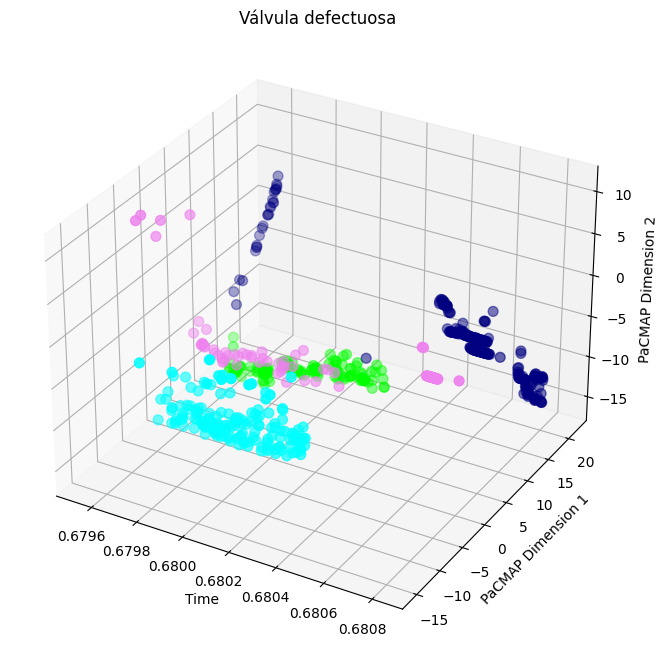

(10, 20) (0, 10)
(-10, 0) (-20, -10)
(-20, -10) (0, 10)
(0, 10) (-10, 0)
(-10, 0) (0, 10)
['indigo', 'violet', 'violet', 'violet', 'violet', 'teal', 'orange', 'teal', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'teal', 'teal', 'indigo', 'indigo', 'indigo', 'indigo', 'teal', 'teal', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'violet', 'orange', 'violet', 'violet', 'violet', 'violet', 'violet', 'teal', 'cyan', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'indigo', 'indigo', 'cyan', 'teal', 'teal', 'violet', 'violet', 'teal', 'cyan', 'cyan', 'indigo', 'teal', 'teal', 'violet', 'cyan', 'indigo', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'orange', 'cyan', 'cyan', 'cyan', 'cyan', 'teal', 'cyan', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'teal', 'cyan', 'teal', 'indigo', 'cyan', 'teal', 'teal', 'orange', 'violet', 'violet', 'cyan', 'teal', 'indigo', 'teal', 'cyan', 'orange', 'violet', 'violet', 'violet', 'orange',

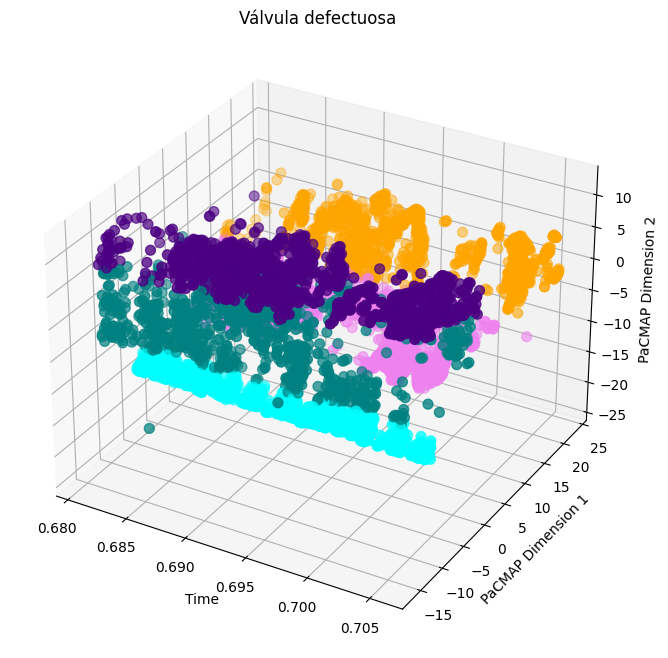

The MOF Falta de aceite hidráulico
(-10, 0) (-20, -10)
(0, 10) (-10, 0)
(20, 30) (0, 10)
(-10, 0) (-10, 0)
(-10, 0) (0, 10)
['teal', 'cyan', 'cyan', 'salmon', 'salmon', 'salmon', 'violet', 'violet', 'violet', 'violet', 'violet', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'salmon', 'salmon', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'salmon', 'violet', 'salmon', 'salmon', 'salmon', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'salmon', 'salmon', 'salmon', 'salmon', 'cyan', 'cyan', 'salmon', 'salmon', 'salmon', 'salmon', 'cyan', 'salmon', 'salmon', 'salmon', 'cyan', 'cyan', 'cyan', 'salmon', 'cyan', 'cyan', 'cyan', 'salmon', 'salmon', 'salmon', 'violet', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'salmon', 'cyan', 'cyan', 'cyan', '

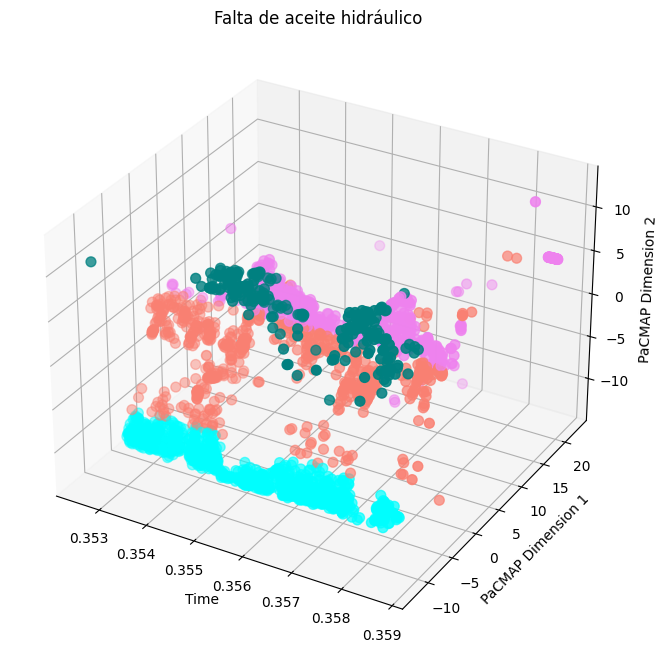

The MOF Lubricación  deficiente
(0, 10) (-20, -10)
(-20, -10) (-10, 0)
(10, 20) (-10, 0)
(-20, -10) (-10, 0)
(-10, 0) (0, 10)
['teal', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'navy', 'navy', 'teal', 'teal', 'teal', 'teal', 'darkgreen', 'navy', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'navy', 'navy', 'navy', 'teal', 'teal', 'teal', 'teal', 'navy', 'navy', 'teal', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen',

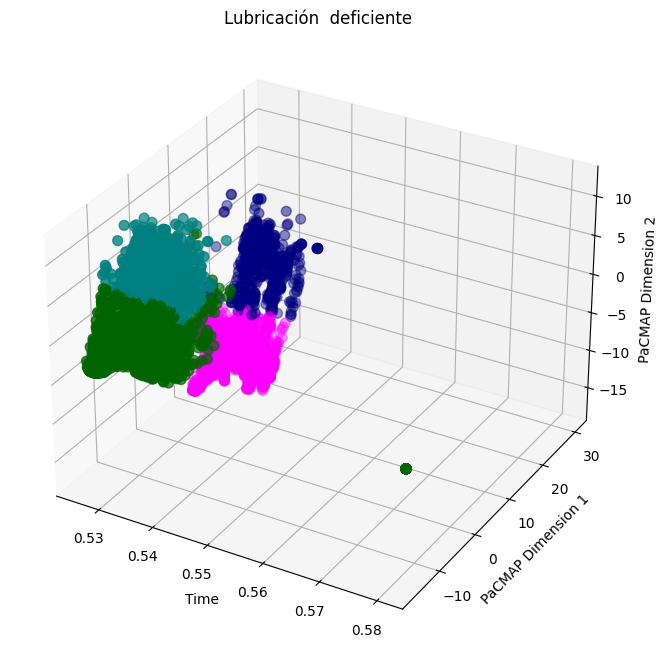

(10, 20) (-20, -10)
(-10, 0) (-10, 0)
(20, 30) (0, 10)
(-10, 0) (0, 10)
(0, 10) (-20, -10)
['violet', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'lime', 'magenta', 'lime', 'magenta', 'magenta', 'lime', 'magenta', 'magenta', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'salmon', 'salmon', 'salmon', 'salmon', 'teal']


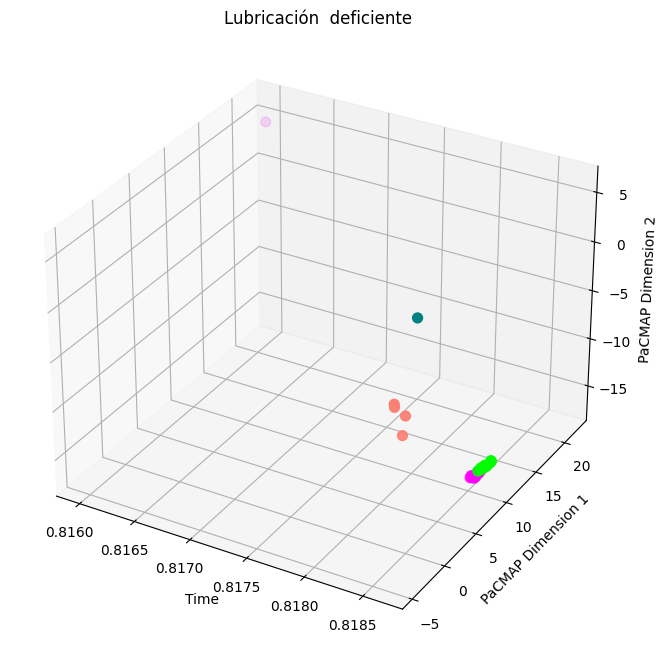

The MOF Temperatura fuera de rango
(-20, -10) (-10, 0)
(10, 20) (-10, 0)
(-20, -10) (0, 10)
(-20, -10) (0, 10)
(0, 10) (-20, -10)
['indigo', 'indigo', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'indigo', 'indigo', 'indigo', 'navy', 'navy', 'navy', 'navy', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'navy', 'indigo', 'indigo', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'magenta', 'magenta', 'magenta', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'indigo', 'magenta', 'magenta', 'magent

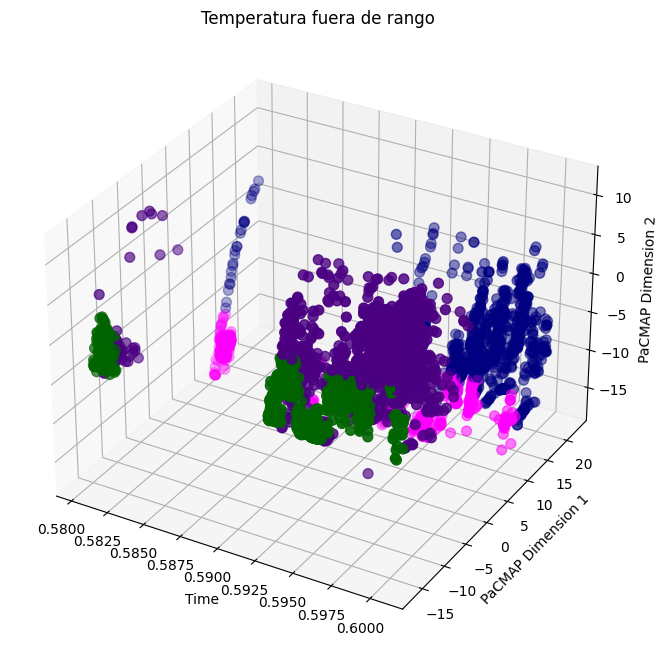

The MOF Bomba hidráulica con fuga
(10, 20) (-20, -10)
(-20, -10) (-10, 0)
(10, 20) (-20, -10)
(20, 30) (0, 10)
(10, 20) (-10, 0)
['darkgreen', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'darkgreen', 'darkgreen', 'lime', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'lime', 'lime', 'lime', 'lime', 'lime', 'darkgreen', 'darkgreen', 'lime', 'lime', 'lime', 'lime', 'lime', 'l

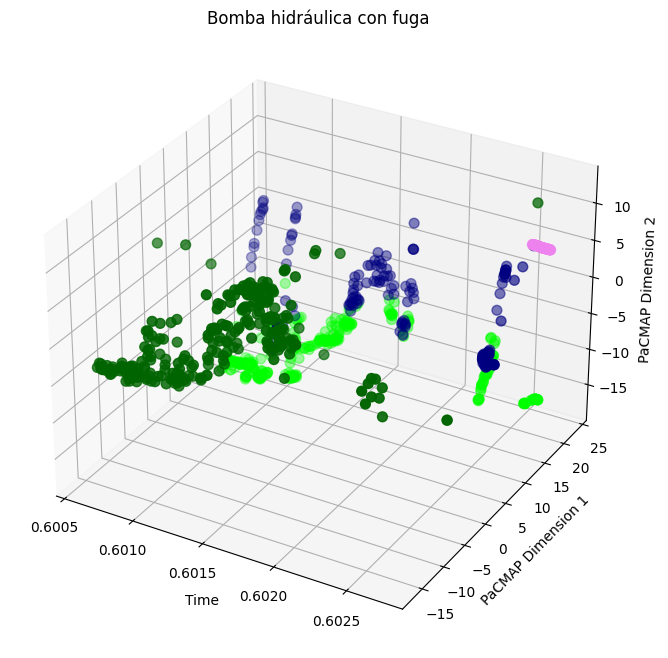

(10, 20) (0, 10)
(0, 10) (0, 10)
(-10, 0) (-10, 0)
(20, 30) (0, 10)
(-10, 0) (-30, -20)
['violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'gold', 'gold', 'gold', 'gold', 'violet', 'violet', 'violet', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'violet', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'violet', 'violet', 'violet', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'orange', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon', 'salmon',

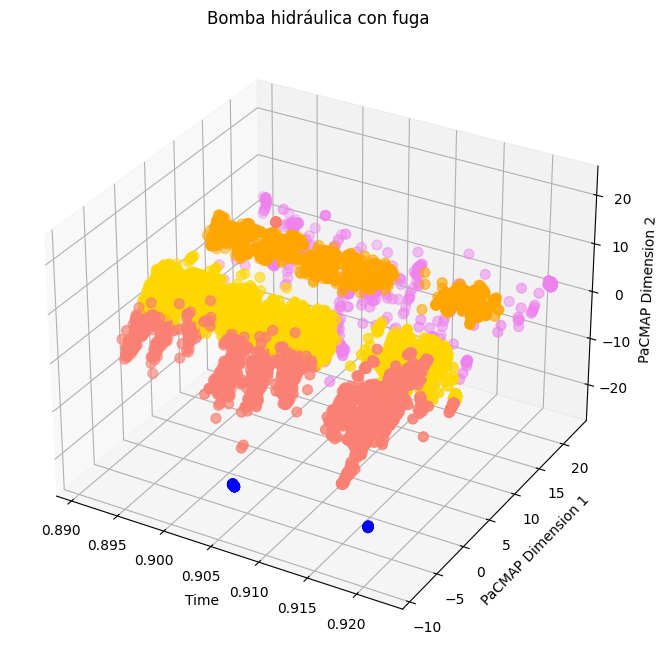

The MOF Fuga de aceite
(0, 10) (-20, -10)
(-10, 0) (0, 10)
(20, 30) (0, 10)
(10, 20) (-10, 0)
(-20, -10) (0, 10)
['magenta', 'magenta', 'teal', 'teal', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'teal', 'indigo', 'indigo', 'indigo', 'teal', 'navy', 'magenta', 'indigo', 'indigo', 'indigo', 'indigo', 'navy', 'magenta', 'magenta', 'magenta', 'magenta', 'teal', 'indigo', 'indigo', 'indigo', 'teal', 'navy', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'magenta', 'navy', 'magenta', 'magenta', 'magenta', 'indigo', 'indigo', 'indigo', 'indigo', 'navy', 'magenta', 'magenta', 'magenta', 'indigo', 'indigo', 'indigo', 'indigo', 'magenta', 'navy', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'indigo', 'indigo', 'indigo', 'indigo', 'teal', 'navy', 'magenta', 'indigo', 'teal', 'indigo', 'teal', 'navy', 'magenta',

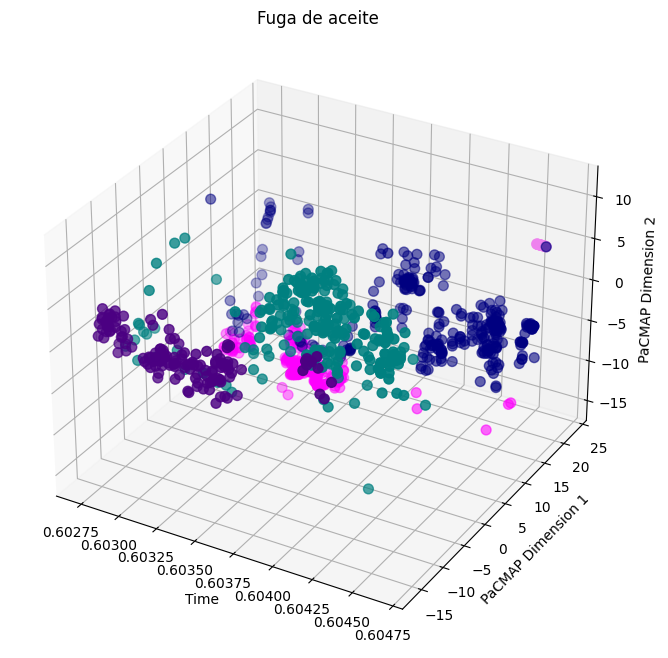

(-20, -10) (0, 10)
(0, 10) (-20, -10)
(-10, 0) (-20, -10)
(10, 20) (-10, 0)
(-10, 0) (0, 10)
['teal', 'magenta', 'magenta', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'indigo', 'indigo', 'indigo', 'indigo', 'magenta', 'magenta', 'magenta', 'magenta', 'magenta', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'magenta', 'indigo', 'indigo', 'indigo', 'teal', 'teal', 'indigo', 'teal', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'indigo', 'teal', 'indigo', 'teal', 'indigo', 'indigo', 'magenta', 'indigo', 'indigo', 'indigo', 'indi

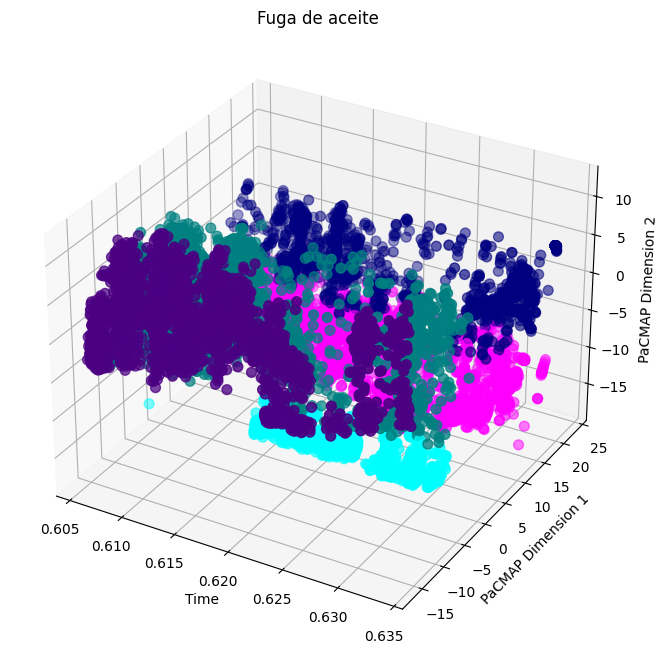

The MOF Falla sistema de hidroset-poste
(-10, 0) (-20, -10)
(10, 20) (-10, 0)
(-10, 0) (0, 10)
(10, 20) (-10, 0)
(10, 20) (-20, -10)
['lime', 'lime', 'cyan', 'cyan', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'teal', 'navy', 'teal', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'lime', 'lime', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'lime', 'lime', 'cyan', 'cyan', 'cyan', 'cyan', 'lime', 'cyan', 'lime', 'navy', 'cyan', 'teal', 'teal', 'teal', 'teal', 'navy', 'cyan', 'teal', 'cyan', 'cyan', 'navy', 'navy', 'navy', 'navy', 'navy', 'lime', 'navy', 'navy', 'cyan', 'cyan', 'lime', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'teal', 'cyan', 'teal', 'teal', 'navy', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'cyan', 'teal', 'teal', 'cyan', 'cyan', 'cyan', 'cyan', 'teal', 'teal', 'navy', 't

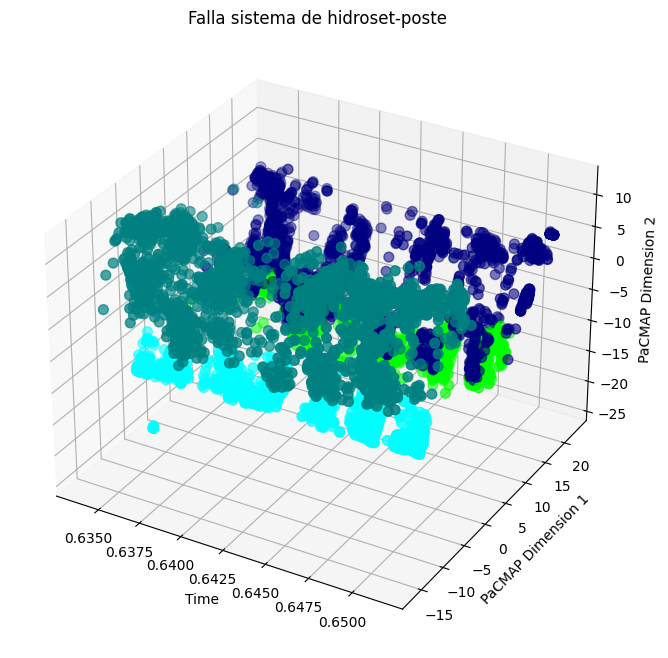

(-10, 0) (-20, -10)
(10, 20) (0, 10)
(-20, -10) (10, 20)
(10, 20) (-10, 0)
(0, 10) (0, 10)
['gold', 'navy', 'cyan', 'orchid', 'orchid', 'orchid', 'orchid', 'gold', 'gold', 'gold', 'orchid', 'orchid', 'orchid', 'cyan', 'orchid', 'orange', 'orchid', 'orchid', 'orchid', 'cyan', 'cyan', 'gold', 'orchid', 'orchid', 'orchid', 'orchid', 'orchid', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'cyan', 'orchid', 'orchid', 'orchid', 'orchid', 'cyan', 'gold', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'orchid', 'orchid', 'cyan', 'orchid', 'cyan', 'orchid', 'navy', 'orchid', 'orchid', 'cyan', 'orchid', 'cyan', 'cyan', 'orchid', 'cyan', 'cyan', 'orchid', 'cyan', 'cyan', 'orange', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'gold', 'cyan', 'orchid', 'orchid', 'cyan', 'orchid', 'navy', 'navy', 'navy', 'navy', 'navy', 'orchid', 'gold', 'navy', 'cyan', 'orchid', 'cyan', 'cyan', 'gold', 'gol

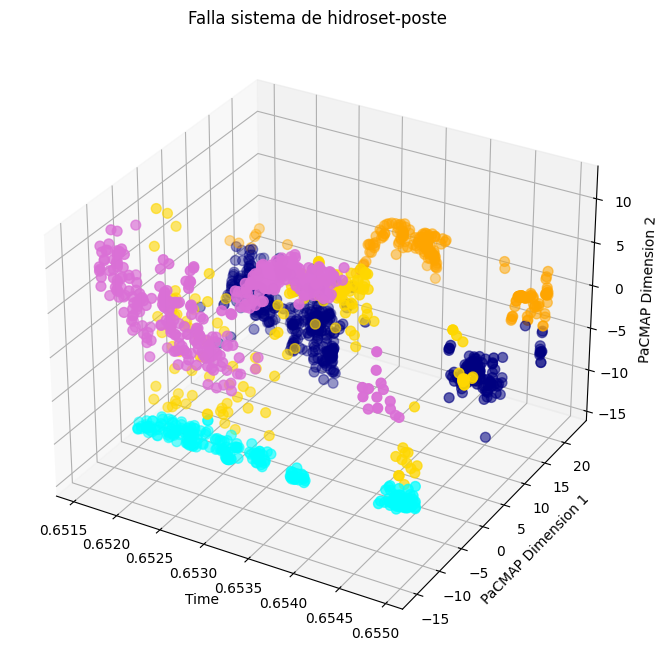

(0, 10) (-10, 0)
(10, 20) (-10, 0)
(10, 20) (-10, 0)
(-10, 0) (-20, -10)
(0, 10) (0, 10)
['gold', 'gold', 'cyan', 'cyan', 'gold', 'gold', 'navy', 'gold', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'gold']


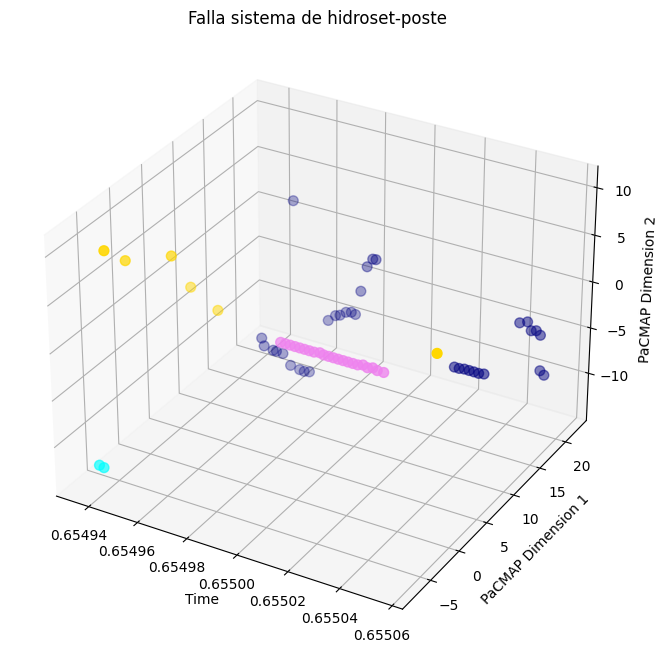

The MOF Mandibulas o revestimiento suelto
(0, 10) (0, 10)
(10, 20) (0, 10)
(0, 10) (0, 10)
(10, 20) (-10, 0)
(-10, 0) (-10, 0)
['orange', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'gold', 'gold', 'gold', 'navy', 'navy', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'navy', 'orange', 'gold', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'gold', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'orange', 'o

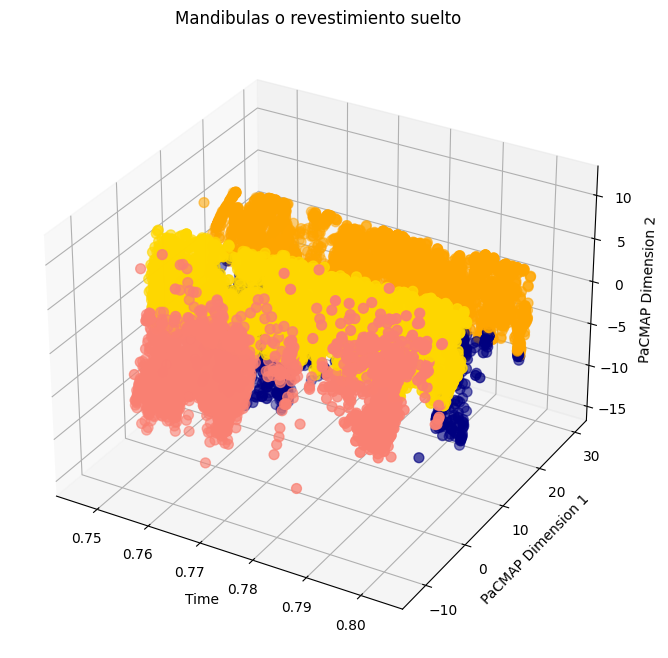

(10, 20) (-10, 0)
(10, 20) (-10, 0)
(-10, 0) (-10, 0)
(10, 20) (0, 10)
(20, 30) (0, 10)
['salmon', 'navy', 'salmon', 'orange', 'violet', 'violet', 'violet', 'violet', 'orange', 'orange', 'orange', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'violet', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'navy', 'navy', 'salmon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'salmon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'salmon', 'navy', 'salmon', 'navy', 'salmon', 'navy', 'salmon', 'salmon', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy

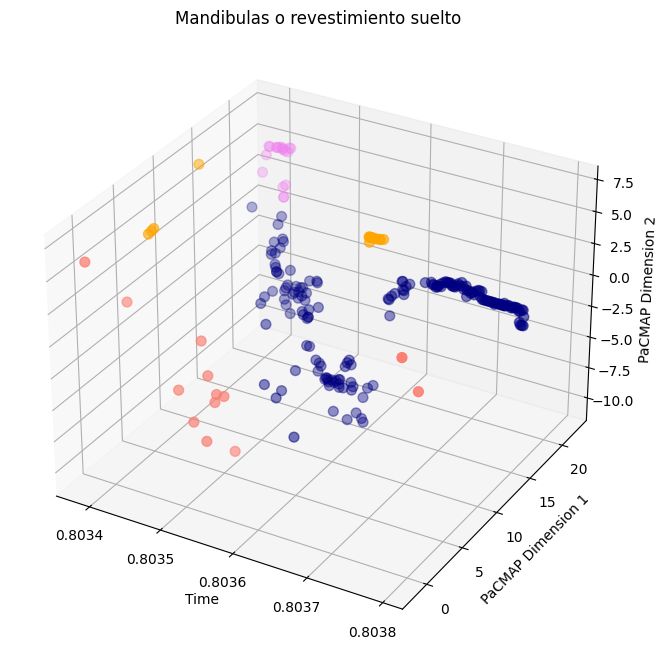

(20, 30) (0, 10)
(10, 20) (0, 10)
(10, 20) (-10, 0)
(-10, 0) (0, 10)
(10, 20) (-10, 0)
['teal', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'violet', 'navy', 'violet', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'teal', 'navy', 'navy', 'navy', 'teal', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'teal', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'orange', 'orange', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 'navy', 

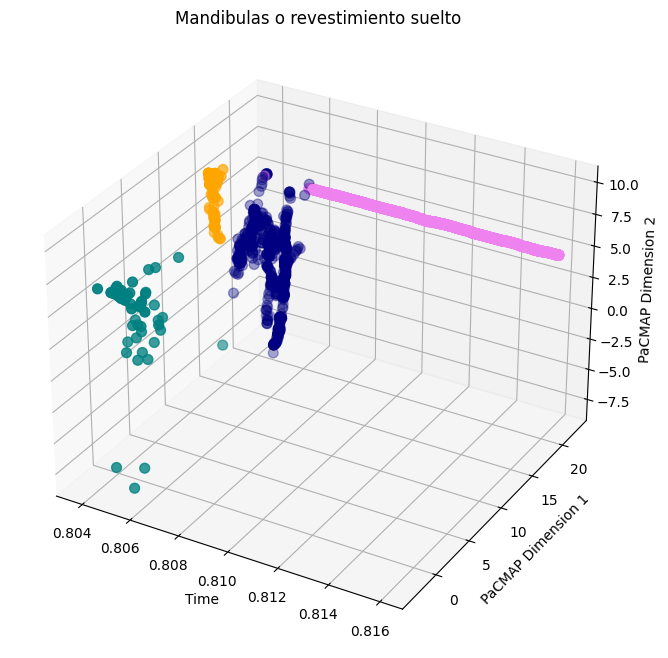

In [49]:
pacmapModel                 = pacmap.PaCMAP(    n_components = 2, 
                                                random_state = 40, 
                                                save_tree    = True)

clusterAlg                  = GaussianMixture(  n_components = 5, 
                                                random_state = 3, 
                                                n_init       = 5)

pacmapModel.fit(normalizedHealthy[preData.beauManipulatedCr1])            # Train with the healthy data

for mof, idxTrajectList in trajectory.items():
    print(f"The MOF {mof}")
    for idx,curTraject in enumerate(idxTrajectList):

        # -----------------------------
        # Transform the PACMAP
        # -----------------------------
        efficiencyTraject   = curTraject[preData.beauManipulatedCr1]     # Extract the 
        # print("--------------------")
        # print(efficiencyTraject.shape)
        embedding           = pacmapModel.transform(efficiencyTraject)
        dim1 = embedding[:, 0]  # First dimension from pacmap (size 100)
        dim2 = embedding[:, 1]  # Second dimension from pacmap (size 100)
        # print(embedding.shape)

        # -----------------------------
        # Cluster
        # -----------------------------
        clusters            = clusterAlg.fit_predict(embedding)
        clusterColor        = [None] * len(clusters)  # Initialize clusterColor to store strings
        clusterDim          = []

        maxCluster          = max(clusters)
        for idx in range(maxCluster+1):
            clusterLabel = idx
            # idxDim       = np.where(clusters == clusterLabel)       # Get the position of current label
            idxDim          = np.where(clusters == clusterLabel)[0]
            # print(idxDim)
            # Step 2: Generate the histogram
            counts1, bins1 = np.histogram(dim1[idxDim])
            max_bin_index1 = np.argmax(counts1)

            counts2, bins2 = np.histogram(dim2[idxDim])
            max_bin_index2 = np.argmax(counts2)

            # Step 4: Get the value of the bin's center with the highest count
            mostDim1 = (bins1[max_bin_index1] + bins1[max_bin_index1 + 1]) / 2
            mostDim2 = (bins2[max_bin_index2] + bins2[max_bin_index2 + 1]) / 2
            # print(mostDim1,mostDim2)

            color   = get_color(int(mostDim1),int(mostDim2))
            if color =="black":
                print(mostDim1,mostDim2)

            for i in idxDim:  # idxDim is a 1D array of indices
                clusterColor[i] = color

        # colorList = np.array(clusterColor)    
        colorList = clusterColor
        print(colorList)
        time       = curTraject["tiempo"]


        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')

        # Plot the data in 3D: X = time, Y = PaCMAP dim 1, Z = PaCMAP dim 2, color by cluster
        scatter = ax.scatter(time, dim1, dim2, c=colorList, s=50)

        # Labels for axes
        ax.set_xlabel('Time')
        ax.set_ylabel('PaCMAP Dimension 1')
        ax.set_zlabel('PaCMAP Dimension 2')

        # Title
        ax.set_title(mof)

        # Add color bar to show cluster information
        # cbar = plt.colorbar(scatter, ax=ax, pad=0.1)
        # cbar.set_label('Cluster')

        # Show plot
        plt.show()
